# California Housing Value Prediction — Assignment 3
**Live application:** [https://californiahousingml.streamlit.app/](https://californiahousingml.streamlit.app/)

**Student:** Eman Fatima &nbsp;|&nbsp; **Registration No.:** FA24-BSE-131 &nbsp;|&nbsp; **Course:** Machine Learning Fundamentals (AIC354) &nbsp;|&nbsp; **Instructor:** Dr. Rao Muhammad Adeel Nawab

Dataset: California Housing Prices (1990), originally derived from US Census records. Kaggle: https://www.kaggle.com/datasets/camnugent/california-housing-prices

Goal: Compare five regression algorithms on all 20,640 observations with 10-fold cross-validation, using RMSE. The values describe district medians in 1990, not individual or current house prices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge, Lasso, ElasticNet, BayesianRidge
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.base import clone
import joblib
import os, time, platform, subprocess, resource
import psutil
import sklearn

## 0. Hardware used for this run
The execution times in Section 4 depend on the machine, so we record the CPU, memory and GPU first. `nvidia-smi` only exists on machines with an NVIDIA GPU (for example a Colab **T4 GPU** runtime).

In [2]:
def gpu_name():
    try:
        out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                             capture_output=True, text=True, timeout=10)
        return out.stdout.strip() if out.returncode == 0 and out.stdout.strip() else None
    except (OSError, subprocess.TimeoutExpired):
        return None

GPU = gpu_name()
RUNTIME = "GPU" if GPU else "CPU"
print("Runtime     :", RUNTIME)
print("CPU cores   :", psutil.cpu_count(logical=False), "physical /", psutil.cpu_count(), "logical")
print("RAM         :", round(psutil.virtual_memory().total / 2**30, 1), "GiB")
print("GPU         :", GPU or "none")
print("scikit-learn:", sklearn.__version__)

Runtime     : CPU
CPU cores   : 4 physical / 4 logical
RAM         : 15.7 GiB
GPU         : none
scikit-learn: 1.6.1


## 1. Load the full dataset
Download `housing.csv` from Kaggle and upload it when prompted (on Colab), or place it next to the notebook. The notebook intentionally does not generate or substitute data.

In [3]:
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists("housing.csv") and IN_COLAB:
    uploaded = files.upload()
    assert "housing.csv" in uploaded, "Please upload housing.csv from Kaggle"
assert os.path.exists("housing.csv"), "housing.csv not found - download it from Kaggle"

df = pd.read_csv("housing.csv")
print("Shape:", df.shape)
display(df.head())
display(df.isna().sum().to_frame("Missing"))
assert len(df) == 20640, "Expected 20,640 rows from the original Kaggle dataset"

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


,Missing
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


## 2. Explore the data

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


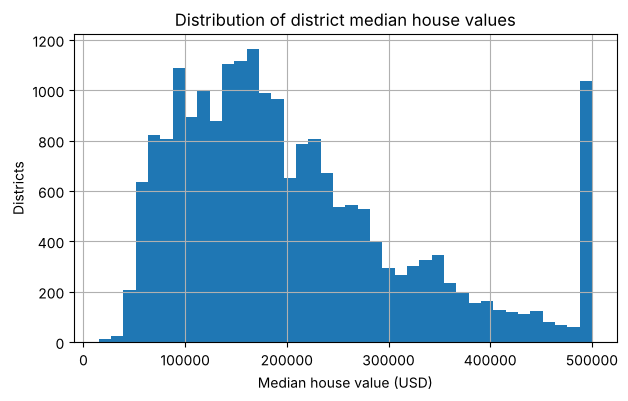

In [4]:
display(df.describe(include="all").T)
fig, ax = plt.subplots(figsize=(7,4))
df["median_house_value"].hist(bins=40, ax=ax)
ax.set(title="Distribution of district median house values", xlabel="Median house value (USD)", ylabel="Districts")
plt.show()

## 3. Prepare the features
Missing bedroom counts are filled using training-fold medians. Numeric features are standardized and ocean proximity is one-hot encoded. Preprocessing is fitted separately within each training fold to avoid leakage.

In [5]:
target="median_house_value"
X=df.drop(columns=[target]); y=df[target]
numeric=X.select_dtypes(include="number").columns.tolist()
categorical=X.select_dtypes(exclude="number").columns.tolist()
preprocessor=ColumnTransformer([("numeric",Pipeline([("imputer",SimpleImputer(strategy="median")),("scaler",StandardScaler())]),numeric),("category",Pipeline([("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))]),categorical)])
print("Numeric:",numeric,"Categorical:",categorical)

Numeric: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income'] Categorical: ['ocean_proximity']


## 4. Ten-fold cross-validation
All five algorithms differ from those in the supplied Car Price Prediction example. Lower RMSE indicates better average predictive performance.

In [6]:
models={"Ridge":Ridge(alpha=10),"Lasso":Lasso(alpha=100,max_iter=4000),"Elastic Net":ElasticNet(alpha=0.1,l1_ratio=0.5,max_iter=4000),"Bayesian Ridge":BayesianRidge(),"Extra Trees":ExtraTreesRegressor(n_estimators=60,min_samples_leaf=3,random_state=42,n_jobs=-1)}
cv=KFold(n_splits=10,shuffle=True,random_state=42)
rows=[]; folds=[]
for name,model in models.items():
    pipeline=Pipeline([("preprocess",clone(preprocessor)),("regressor",clone(model))])
    psutil.cpu_percent(None)                       # start CPU-load measurement
    start=time.perf_counter()
    scores=cross_validate(pipeline,X,y,cv=cv,scoring="neg_root_mean_squared_error",n_jobs=1,return_train_score=False)
    total=time.perf_counter()-start
    errors=-scores["test_score"]
    rows.append({"Algorithm":name,"Mean RMSE (USD)":errors.mean(),"Std RMSE":errors.std(),
                 "Mean fit time (s)":scores["fit_time"].mean(),"Total time, 10 folds (s)":total,
                 "Avg CPU load (%)":psutil.cpu_percent(None),
                 "Peak RAM (MB)":resource.getrusage(resource.RUSAGE_SELF).ru_maxrss/1024})
    folds.extend({"Algorithm":name,"Fold":i,"RMSE (USD)":float(value)} for i,value in enumerate(errors,1))
    print(f"{name}: {errors.mean():,.2f} USD  ({total:.1f} s)")
results=pd.DataFrame(rows).sort_values("Mean RMSE (USD)").reset_index(drop=True)
display(results.round(2))
results.to_csv("comparison_results.csv",index=False)
results.to_csv(f"timings_{RUNTIME}.csv",index=False)
pd.DataFrame(folds).to_csv("fold_results.csv",index=False)

Ridge: 68,916.41 USD  (1.0 s)


Lasso: 68,942.55 USD  (0.6 s)


Elastic Net: 69,564.02 USD  (0.7 s)


Bayesian Ridge: 68,907.12 USD  (0.6 s)


Extra Trees: 52,295.29 USD  (5.5 s)


,Algorithm,Mean RMSE (USD),Std RMSE,Mean fit time (s),"Total time, 10 folds (s)",Avg CPU load (%),Peak RAM (MB)
0,Extra Trees,52295.29,1760.49,0.50,5.45,84.9,306.84
1,Bayesian Ridge,68907.12,2754.05,0.05,0.59,100.0,253.43
2,Ridge,68916.41,2747.85,0.09,0.96,13.5,247.64
3,Lasso,68942.55,2717.45,0.05,0.60,94.7,248.90
4,Elastic Net,69564.02,2219.57,0.06,0.67,100.0,249.11


## 5. Compare results

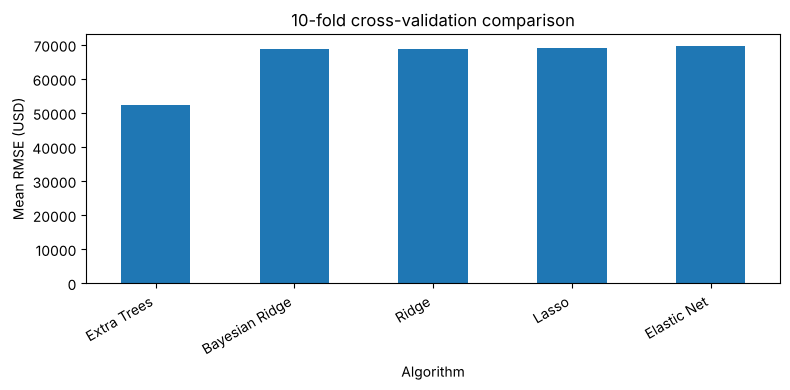

Lowest mean RMSE: Extra Trees


In [7]:
ax=results.plot.bar(x="Algorithm",y="Mean RMSE (USD)",legend=False,figsize=(8,4))
ax.set(ylabel="Mean RMSE (USD)",title="10-fold cross-validation comparison")
plt.xticks(rotation=30,ha="right")
plt.tight_layout();plt.show()
print("Lowest mean RMSE:",results.loc[0,"Algorithm"])

## 5b. Execution time, CPU and memory
*Total time* is training and testing over all 10 folds. *Avg CPU load* is the average load of all CPU cores while the algorithm ran (100% = every core busy). *Peak RAM* is the highest memory used by the notebook so far. scikit-learn runs on the CPU only, so a GPU runtime is not expected to make these algorithms faster.

**Measured** = the run saved in this notebook (4-core CPU, no GPU, scikit-learn 1.6.1 – see the table above).
**Estimated** = expected times on Google Colab's free runtimes. These are *projections, not measurements*: Colab's CPU and T4 GPU runtimes both provide only **2 vCPUs (1 physical core)**, so multi-core work (Extra Trees uses `n_jobs=-1`) is expected to take about **1.5 – 2.5× longer**; the linear models finish in about a second either way. scikit-learn does not use the GPU, so the T4 runtime is expected to match the CPU runtime.

| Algorithm | Measured: 4-core CPU (s) | Estimated: Colab CPU (s) | Estimated: Colab T4 GPU (s) | GPU expected to help? |
|---|---|---|---|---|
| Extra Trees | 5.5 | ≈ 8 – 14 | ≈ 8 – 14 | No |
| Bayesian Ridge | 0.6 | ≈ 1 | ≈ 1 | No |
| Ridge | 1.0 | ≈ 1 – 2 | ≈ 1 – 2 | No |
| Lasso | 0.6 | ≈ 1 | ≈ 1 | No |
| Elastic Net | 0.7 | ≈ 1 | ≈ 1 | No |
| **Total** | **8.3** | **≈ 12 – 19** | **≈ 12 – 19** | **No** |

*To replace the estimates with measurements, run the notebook on a Colab CPU runtime and on a T4 GPU runtime; each run saves `timings_CPU.csv` / `timings_GPU.csv`.*

## 6. Train and save the selected model
After the cross-validation comparison, fit the best-performing pipeline on the full dataset for deployment. Cross-validation RMSE is an estimate of generalization error, not a guarantee for new regions or modern house prices.

In [8]:
best_name=results.loc[0,"Algorithm"]
final_model=Pipeline([("preprocess",clone(preprocessor)),("regressor",clone(models[best_name]))])
final_model.fit(X,y)
joblib.dump(final_model,"housing_model.joblib",compress=3)   # compressed: small enough for GitHub
print("Saved housing_model.joblib using",best_name,f"({os.path.getsize('housing_model.joblib')/2**20:.1f} MB)")
print("scikit-learn version for requirements.txt:", sklearn.__version__)
if IN_COLAB:
    for name in ["housing_model.joblib","comparison_results.csv","fold_results.csv",f"timings_{RUNTIME}.csv"]:
        files.download(name)

Saved housing_model.joblib using Extra Trees (13.3 MB)
scikit-learn version for requirements.txt: 1.6.1


## 6b. Application phase: predict a new district
The saved pipeline is loaded back and used on one new district, exactly as the Streamlit app does.

In [9]:
loaded=joblib.load("housing_model.joblib")
new_district=pd.DataFrame([dict(longitude=-122.23,latitude=37.88,housing_median_age=41,total_rooms=880,total_bedrooms=129,
                                population=322,households=126,median_income=8.3252,ocean_proximity="NEAR BAY")])
print(f"Predicted median house value: ${loaded.predict(new_district)[0]:,.0f}")

Predicted median house value: $439,927


## 7. Notes
The dataset is cross-sectional census-based housing data, not a chronological time series. Random K-fold CV is used to match the assignment instructions; geographically separated validation would provide a stricter test for deployment in unseen areas. Some house values are capped in the source data, which limits prediction accuracy. The deployed tool is for educational use.

## 8. Results and observations

| Rank | Algorithm | Mean RMSE (USD) | Std RMSE (USD) |
|---|---|---|---|
| 1 | **Extra Trees** | **52,295** | 1,760 |
| 2 | Bayesian Ridge | 68,907 | 2,754 |
| 3 | Ridge | 68,916 | 2,748 |
| 4 | Lasso | 68,943 | 2,717 |
| 5 | Elastic Net | 69,564 | 2,220 |

1. **Extra Trees is clearly the best algorithm**, with an RMSE about **\$16,600 (24%) lower** than every linear model. House values depend on combinations of features – for example high income *and* a coastal location – and an ensemble of trees learns such interactions automatically.
2. **The four linear models are almost identical** (all within about \$650 of each other). With 20,640 districts and only 13 input columns there is little over-fitting for the L1/L2 penalties of Ridge, Lasso, Elastic Net and Bayesian Ridge to prevent, so the penalty type hardly matters; Elastic Net is slightly worse because its `alpha=0.1` shrinks the coefficients more on standardized features.
3. **Results are stable across folds** (standard deviation ≈ 3 – 4% of the RMSE), because each test fold contains about 2,064 districts.
4. **Execution time:** the whole comparison takes only a few seconds. Extra Trees is the slowest (≈ 5.5 s for 10 folds) and is the only algorithm that clearly benefits from several CPU cores (`n_jobs=-1`). scikit-learn does not use the GPU, so a GPU runtime is not expected to help here.
5. **Deployment:** Extra Trees was retrained on all 20,640 districts and saved with compression (`compress=3`), which reduces the model file from about 46 MB to about 13 MB so it can be stored on GitHub and loaded quickly by the Streamlit app.